# 01 · EDA, Stationarity and ARMA Identification (Lectures 1–20)

**Data:** `data/processed/yellowstone_master_ts_flagged.csv` (annual, 1984–2025).
**Target:** northern Yellowstone elk counts.

Sections
1. Exploratory plots (imputed values marked)
2. Trend estimation and smoothing
3. Stationarity tests (ADF + KPSS)
4. ACF / PACF of the stationary elk series
5. Structural break at 1995 (Chow test)
6. ARMA model selection + Yule–Walker
7. Residual diagnostics

Figures are saved to `reports/figures/`.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy import stats
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller, kpss

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(ROOT / "data" / "processed" / "yellowstone_master_ts_flagged.csv", index_col="Year")
VARS = ["Elk_Count", "Wolf_Northern", "Bison_Count", "NDVI", "Precip_Annual", "PDSI_Annual"]
LABELS = {"Elk_Count": "Elk (count)", "Wolf_Northern": "Wolves, northern range",
          "Bison_Count": "Bison (northern herd)", "NDVI": "Summer NDVI",
          "Precip_Annual": "Precipitation (mm, water year)", "PDSI_Annual": "PDSI (drought index)"}
REINTRO = 1995
df[VARS].describe().round(2)

,Elk_Count,Wolf_Northern,Bison_Count,NDVI,Precip_Annual,PDSI_Annual
count,42.00,42.00,42.00,42.00,42.00,42.00
mean,10098.02,40.45,1979.05,0.52,571.05,-0.36
std,5064.47,29.57,1472.24,0.04,67.85,2.22
min,3804.00,0.00,432.00,0.41,426.35,-4.85
25%,5539.25,5.25,808.25,0.50,525.14,-2.08
50%,8801.00,40.50,1258.50,0.51,575.09,-0.42
75%,14751.75,57.75,3423.00,0.55,606.38,1.41
max,19048.00,98.00,5300.00,0.59,696.16,3.53


## 1. Exploratory plots
Hollow red points are imputed values (see the `*_source` columns). Dashed line = 1995 wolf reintroduction.

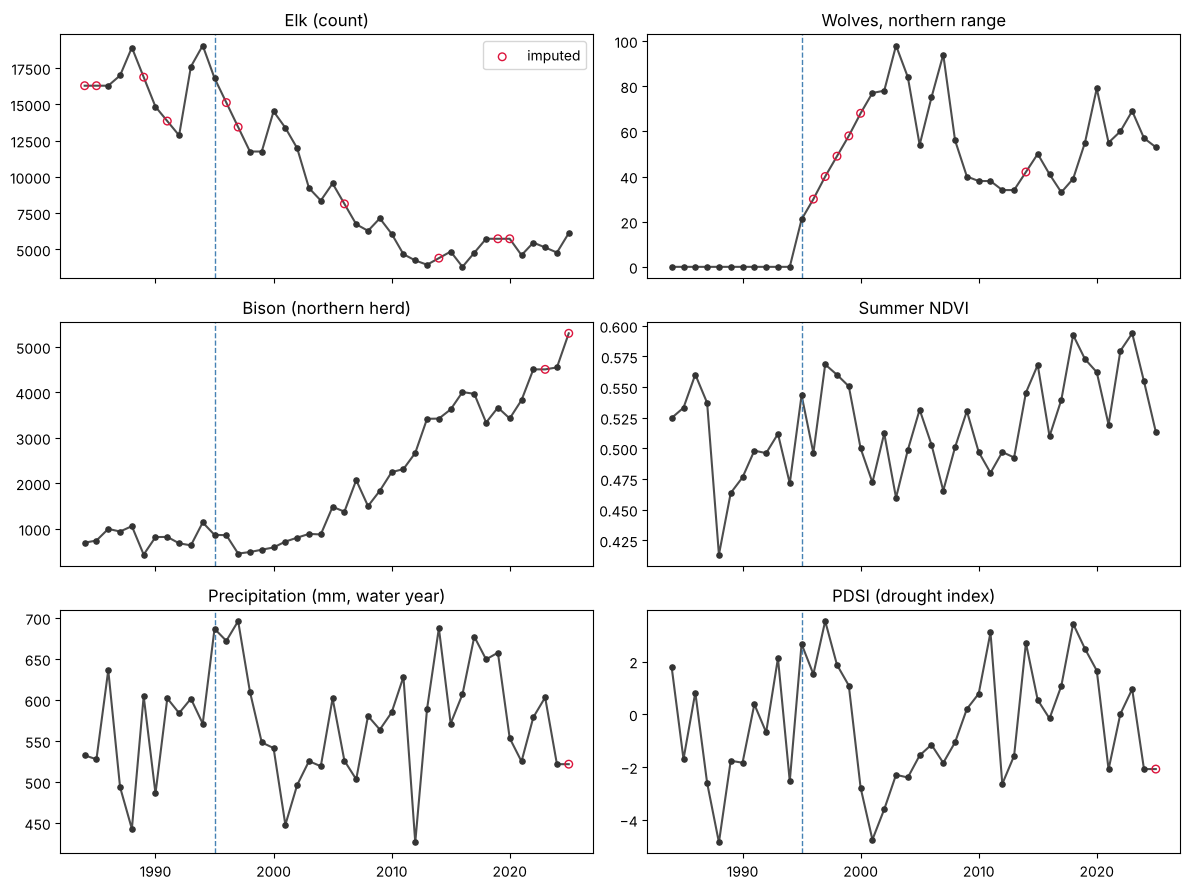

In [2]:
fig, axes = plt.subplots(3, 2, figsize=(12, 9), sharex=True)
for ax, col in zip(axes.flat, VARS):
    imp = df[f"{col}_imputed"] == 1
    ax.plot(df.index, df[col], color="0.3", lw=1.5)
    ax.scatter(df.index[~imp], df.loc[~imp, col], s=14, color="0.2", zorder=3)
    ax.scatter(df.index[imp], df.loc[imp, col], s=30, facecolors="none", edgecolors="crimson", zorder=4, label="imputed")
    ax.axvline(REINTRO, ls="--", color="steelblue", lw=1)
    ax.set_title(LABELS[col])
axes[0, 0].legend(loc="upper right")
fig.tight_layout()
fig.savefig(FIG / "01_all_series.png", dpi=200)

### Correlations
Correlations between **levels** of trending series can be spurious (two series that both trend look related).
Correlations between **first differences** are the more honest check.

In [3]:
levels = df[VARS].corr().round(2)
diffs = df[VARS].diff().dropna().corr().round(2)
print("Correlation with elk — levels vs first differences")
pd.DataFrame({"levels": levels["Elk_Count"], "differences": diffs["Elk_Count"]}).drop("Elk_Count")

Correlation with elk — levels vs first differences


,levels,differences
Wolf_Northern,-0.59,-0.19
Bison_Count,-0.80,0.15
NDVI,-0.32,-0.08
Precip_Annual,-0.09,-0.06
PDSI_Annual,-0.18,-0.14


## 2. Trend estimation and smoothing (elk)

,model,RSS,AIC,BIC,adj_R2
0,linear,1.722789e+08,762.723,766.198,0.832
1,quadratic,1.539984e+08,760.012,765.225,0.846
2,cubic,7.820178e+07,733.550,740.501,0.920


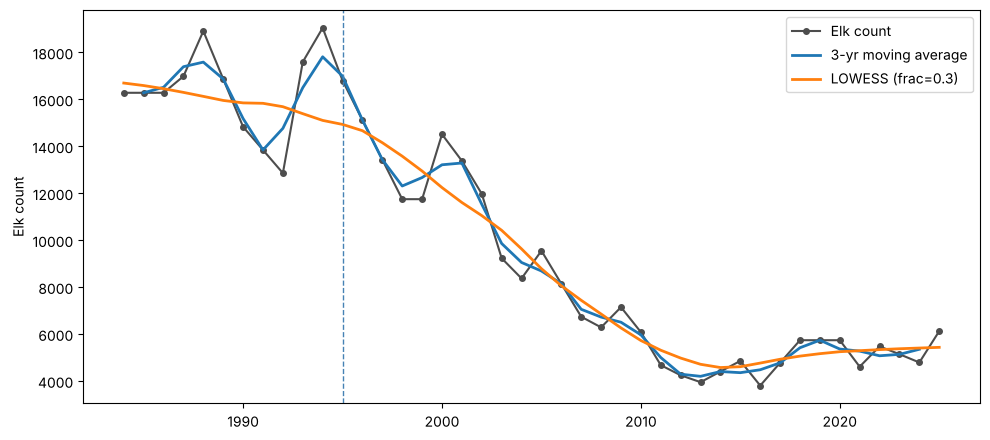

In [4]:
elk = df["Elk_Count"]
t = np.arange(len(elk))
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(elk.index, elk, "o-", color="0.3", ms=4, label="Elk count")
ax.plot(elk.index, elk.rolling(3, center=True).mean(), lw=2, label="3-yr moving average")
low = sm.nonparametric.lowess(elk.values, elk.index.values, frac=0.3)
ax.plot(low[:, 0], low[:, 1], lw=2, label="LOWESS (frac=0.3)")
ax.axvline(REINTRO, ls="--", color="steelblue", lw=1)
ax.set_ylabel("Elk count"); ax.legend()
fig.tight_layout(); fig.savefig(FIG / "02_elk_smoothing.png", dpi=200)

rows = []
for name, deg in [("linear", 1), ("quadratic", 2), ("cubic", 3)]:
    X = sm.add_constant(np.column_stack([t**k for k in range(1, deg + 1)]))
    m = sm.OLS(elk.values, X).fit()
    rows.append({"model": name, "RSS": m.ssr, "AIC": m.aic, "BIC": m.bic, "adj_R2": m.rsquared_adj})
pd.DataFrame(rows).round(3)

## 3. Stationarity tests
- **ADF**: H0 = unit root (non-stationary). Small p-value → stationary.
- **KPSS**: H0 = stationary. Small p-value → non-stationary.

Using both guards against the weakness of each. A series is called stationary when ADF rejects and KPSS does not.

In [5]:
def stationarity(x, name):
    x = pd.Series(x).dropna()
    adf = adfuller(x, autolag="AIC")
    kp = kpss(x, regression="c", nlags="auto")
    return {"series": name, "n": len(x), "ADF_stat": adf[0], "ADF_p": adf[1], "ADF_lags": adf[2],
            "KPSS_stat": kp[0], "KPSS_p": kp[1],
            "verdict": "stationary" if (adf[1] < 0.05 and kp[1] > 0.05) else
                       "non-stationary" if (adf[1] >= 0.05 and kp[1] <= 0.05) else "inconclusive"}

rows = []
for col in VARS:
    rows.append(stationarity(df[col], f"{col} (level)"))
    rows.append(stationarity(df[col].diff(), f"{col} (1st diff)"))
rows.append(stationarity(np.log(elk), "Elk (log)"))
rows.append(stationarity(np.log(elk).diff(), "Elk (log diff)"))
st = pd.DataFrame(rows).round(3)
st.to_csv(FIG / "03_stationarity.csv", index=False)
st

,series,n,ADF_stat,ADF_p,ADF_lags,KPSS_stat,KPSS_p,verdict
0,Elk_Count (level),42,-1.161,0.690,0,0.860,0.010,non-stationary
1,Elk_Count (1st diff),41,-5.549,0.000,1,0.168,0.100,stationary
2,Wolf_Northern (level),42,-2.952,0.040,8,0.467,0.049,inconclusive
3,Wolf_Northern (1st diff),41,-3.148,0.023,2,0.144,0.100,stationary
4,Bison_Count (level),42,1.300,0.997,1,0.840,0.010,non-stationary
5,Bison_Count (1st diff),41,-7.729,0.000,0,0.311,0.100,stationary
6,NDVI (level),42,-3.790,0.003,0,0.406,0.075,stationary
7,NDVI (1st diff),41,-5.682,0.000,2,0.242,0.100,stationary
8,Precip_Annual (level),42,-4.660,0.000,0,0.101,0.100,stationary
9,Precip_Annual (1st diff),41,-2.973,0.037,6,0.406,0.074,stationary


## 4. ACF / PACF of the stationary elk series (log-differences)
With n ≈ 41, only lags up to ~10 are meaningful.

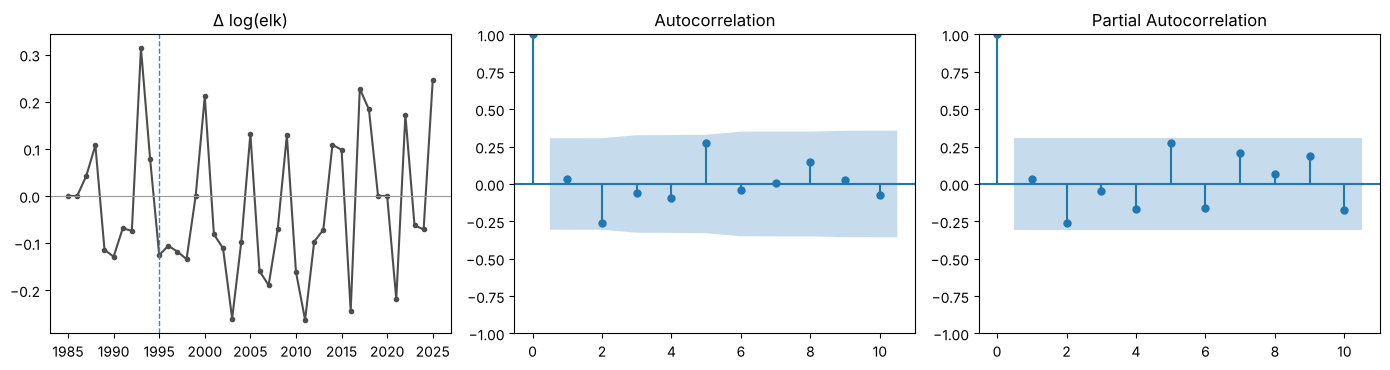

In [6]:
y = np.log(elk).diff().dropna()
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
axes[0].plot(y.index, y, "o-", ms=3, color="0.3"); axes[0].axhline(0, color="0.6", lw=0.8)
axes[0].axvline(REINTRO, ls="--", color="steelblue", lw=1); axes[0].set_title("Δ log(elk)")
plot_acf(y, lags=10, ax=axes[1]); plot_pacf(y, lags=10, ax=axes[2], method="ywm")
fig.tight_layout(); fig.savefig(FIG / "04_elk_acf_pacf.png", dpi=200)

## 5. Structural break at 1995 (Chow test)
Regression of log(elk) on time, fitted separately before and after 1995.
H0: same intercept and slope in both periods.

In [7]:
def chow(y, x, split_year):
    X = sm.add_constant(x)
    pre, post = y.index < split_year, y.index >= split_year
    full = sm.OLS(y, X).fit()
    m1 = sm.OLS(y[pre], X[pre]).fit(); m2 = sm.OLS(y[post], X[post]).fit()
    k, n = X.shape[1], len(y)
    F = ((full.ssr - (m1.ssr + m2.ssr)) / k) / ((m1.ssr + m2.ssr) / (n - 2 * k))
    return F, 1 - stats.f.cdf(F, k, n - 2 * k), m1.params.iloc[1], m2.params.iloc[1]

ly = np.log(elk)
F, p, b_pre, b_post = chow(ly, pd.Series(t, index=ly.index, name="t"), REINTRO)
print(f"Chow F = {F:.2f}, p = {p:.4f}")
print(f"Trend in log(elk) per year: before 1995 = {b_pre:+.3f}, from 1995 = {b_post:+.3f}")
print("(a slope of -0.05 is roughly a 5% decline per year)")

Chow F = 1.73, p = 0.1906
Trend in log(elk) per year: before 1995 = -0.002, from 1995 = -0.042
(a slope of -0.05 is roughly a 5% decline per year)


## 6. ARMA model selection on Δ log(elk)
Candidates are fitted to the stationary series. Lower AIC/BIC is better; a Ljung–Box p-value above 0.05 means the residuals look like white noise.
If scores are close, prefer the simpler model.

In [8]:
cands = [(0, 0), (1, 0), (2, 0), (0, 1), (0, 2), (1, 1)]
rows, fits = [], {}
for p_, q_ in cands:
    m = ARIMA(y, order=(p_, 0, q_), trend="c").fit()
    fits[(p_, q_)] = m
    lb = acorr_ljungbox(m.resid, lags=[8]).lb_pvalue.iloc[0]
    rows.append({"model": "white noise" if (p_, q_) == (0, 0) else f"ARMA({p_},{q_})",
                 "AIC": m.aic, "BIC": m.bic, "LjungBox_p(lag8)": lb,
                 "params": ", ".join(f"{k}={v:.3f}" for k, v in m.params.items() if k != "sigma2")})
sel = pd.DataFrame(rows).sort_values("BIC").round(3)
sel.to_csv(FIG / "06_arma_selection.csv", index=False)
sel

,model,AIC,BIC,LjungBox_p(lag8),params
0,white noise,-38.217,-34.790,0.385,const=-0.024
4,"ARMA(0,2)",-40.308,-33.454,0.608,"const=-0.027, ma.L1=0.261, ma.L2=-0.542"
5,"ARMA(1,1)",-40.198,-33.343,0.654,"const=-0.023, ar.L1=-0.637, ma.L1=0.973"
3,"ARMA(0,1)",-36.328,-31.187,0.365,"const=-0.023, ma.L1=0.079"
1,"ARMA(1,0)",-36.267,-31.127,0.376,"const=-0.024, ar.L1=0.036"
2,"ARMA(2,0)",-37.278,-30.424,0.508,"const=-0.025, ar.L1=0.050, ar.L2=-0.272"


### Yule–Walker vs maximum likelihood for AR(1)

In [9]:
rho, sigma = sm.regression.yule_walker(y.values - y.mean(), order=1, method="mle")
ml = fits[(1, 0)].params
print(f"AR(1) phi — Yule–Walker: {rho[0]:.3f}   |   MLE: {ml['ar.L1']:.3f}")

AR(1) phi — Yule–Walker: 0.034   |   MLE: 0.036


## 7. Residual diagnostics for the best model (lowest BIC)

Shapiro–Wilk normality p = 0.122


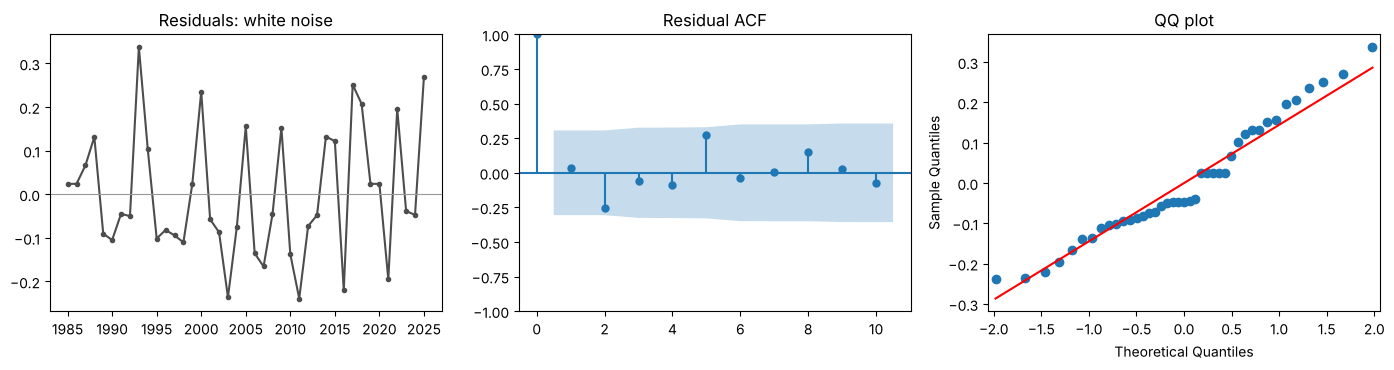

In [10]:
best_key = cands[[r["model"] for r in rows].index(sel.iloc[0]["model"])]
best = fits[best_key]
r = best.resid
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
axes[0].plot(r.index, r, "o-", ms=3, color="0.3"); axes[0].axhline(0, color="0.6", lw=0.8)
axes[0].set_title(f"Residuals: {sel.iloc[0]['model']}")
plot_acf(r, lags=10, ax=axes[1]); axes[1].set_title("Residual ACF")
sm.qqplot(r, line="s", ax=axes[2]); axes[2].set_title("QQ plot")
fig.tight_layout(); fig.savefig(FIG / "07_residuals.png", dpi=200)
print("Shapiro–Wilk normality p =", round(stats.shapiro(r).pvalue, 3))

## Takeaways (fill in after running)
1. Which series are stationary in levels, and which need differencing?
2. What do the ACF/PACF of Δ log(elk) suggest?
3. Is there a significant break at 1995, and how did the elk trend change?
4. Which ARMA model is selected, and do its residuals pass the checks?

**Caveats to state:** 10 of 42 elk values are imputed (smoothing them can inflate autocorrelation); the 2016+ elk values come from a different survey (HD 313).